In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
t = pd.DataFrame({"time": [0.2, 0.9, 1.1, 1.8, 2.4, 2.6], "speed": [5, 40, 12, 7, 90, 3]})

In [3]:
t["speed"] > 10

0    False
1     True
2     True
3    False
4     True
5    False
Name: speed, dtype: bool

In [4]:
df = pd.read_csv("/Users/arnavchouksey/kinetisense/data/synthetic/synthetic_1000hz.csv")

In [5]:
events = pd.read_csv("/Users/arnavchouksey/kinetisense/data/synthetic/synthetic_events.csv")

In [6]:
df.shape

(60000, 7)

In [7]:
events.shape


(16, 3)

In [8]:
events


,event_time_s,label,true_peak_dps
0,5.393809,throw,5021.216869
1,9.143809,not_throw,385.504934
2,11.928604,throw,2157.502763
3,15.678604,not_throw,383.712589
4,18.971310,throw,2974.022361
5,22.721310,not_throw,512.227985
6,27.120936,throw,4907.067178
7,30.870936,not_throw,702.249023
8,33.459940,throw,5047.055059
9,37.209940,not_throw,694.600190


In [9]:
df.shape

(60000, 7)

In [10]:
events.shape


(16, 3)

In [11]:
events.iloc[6]


event_time_s       27.120936
label                  throw
true_peak_dps    4907.067178
Name: 6, dtype: object

In [12]:
events["true_peak_dps"].value_counts()

true_peak_dps
5021.216869    1
385.504934     1
2157.502763    1
383.712589     1
2974.022361    1
512.227985     1
4907.067178    1
702.249023     1
5047.055059    1
694.600190     1
3144.810593    1
567.126819     1
4555.785182    1
532.795266     1
4119.960431    1
885.349337     1
Name: count, dtype: int64

In [13]:
throws = events[events["label"] == "throw"]
swings = events[events["label"] == "not_throw"]

In [14]:
throws


,event_time_s,label,true_peak_dps
0,5.393809,throw,5021.216869
2,11.928604,throw,2157.502763
4,18.971310,throw,2974.022361
6,27.120936,throw,4907.067178
8,33.459940,throw,5047.055059
10,39.861702,throw,3144.810593
12,47.738363,throw,4555.785182
14,54.170801,throw,4119.960431


In [15]:
swings

,event_time_s,label,true_peak_dps
1,9.143809,not_throw,385.504934
3,15.678604,not_throw,383.712589
5,22.721310,not_throw,512.227985
7,30.870936,not_throw,702.249023
9,37.209940,not_throw,694.600190
11,43.611702,not_throw,567.126819
13,51.488363,not_throw,532.795266
15,57.920801,not_throw,885.349337


In [16]:
swings.shape

(8, 3)

In [17]:
gyro_mag = np.sqrt(df['gx']**2 + df['gy']**2 + df['gz']**2)#Ported over from notebook 1 load and plot.ipynb
gyro_mag

0        1.964248
1        5.645461
2        3.327207
3        6.533779
4        0.762138
           ...   
59995    2.486520
59996    7.102971
59997    3.056473
59998    4.761211
59999    4.929092
Length: 60000, dtype: float64

In [18]:
gyro_mag.shape
#gyro_mag tells us how fast the forearm is rotating overall, this si the number we care about. Pythagarean theorum in 3 directions

(60000,)

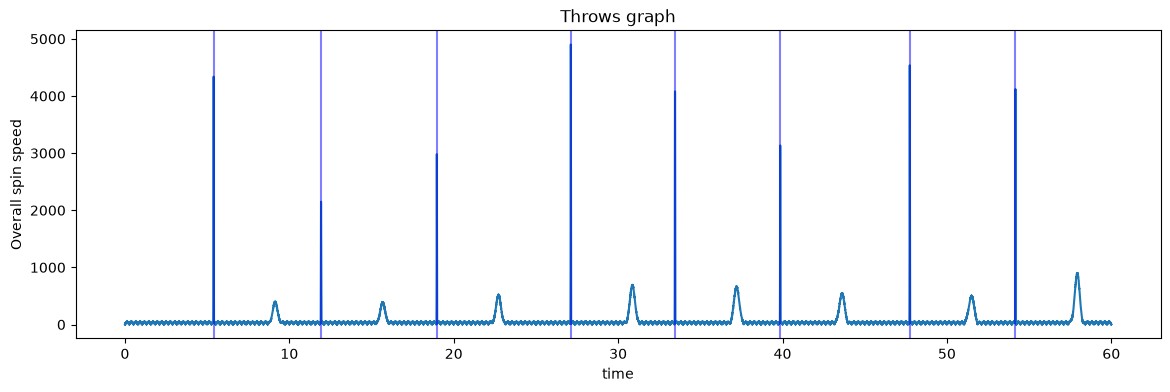

In [19]:
plt.figure(figsize=(14,4))
plt.plot(df['time_s'], gyro_mag)
for i in throws['event_time_s']:
    plt.axvline(x=i,color="blue",alpha=0.5)
plt.title("Throws graph")
plt.xlabel('time')
plt.ylabel('Overall spin speed')
plt.show()

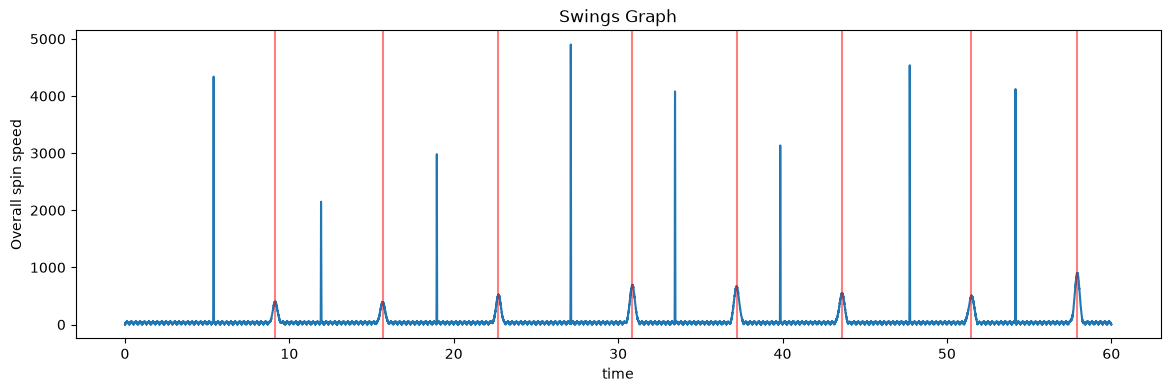

In [20]:
plt.figure(figsize=(14,4))
plt.plot(df['time_s'],gyro_mag)
for i in swings['event_time_s']:
    plt.axvline(i,color="red", alpha=0.5)
plt.title("Swings Graph")
plt.xlabel("time")
plt.ylabel("Overall spin speed")
plt.show()

In [21]:
df

,time_s,gx,gy,gz,ax,ay,az
0,0.000,0.314700,-1.607008,1.084785,0.002820,0.012064,0.981732
1,0.001,4.302834,3.144411,-1.862668,-0.014538,0.021140,1.019863
2,0.002,-3.014653,-1.263530,0.621019,-0.010477,0.003275,1.018717
3,0.003,-5.802815,0.252957,-2.992260,0.048790,0.017633,0.983330
4,0.004,-0.634025,-0.420535,0.044897,0.004248,-0.002296,1.021145
...,...,...,...,...,...,...,...
59995,59.995,-0.744222,-1.279341,1.998049,0.011971,-0.025193,0.972145
59996,59.996,-5.404739,-2.321580,-3.981364,-0.023924,-0.024352,0.983035
59997,59.997,-0.528172,2.480683,1.705658,-0.012265,0.020655,0.999053
59998,59.998,-4.696312,-0.746099,-0.238987,-0.036442,-0.005642,1.003420


In [22]:

len(df['time_s'])


60000

In [23]:

len(gyro_mag)

60000

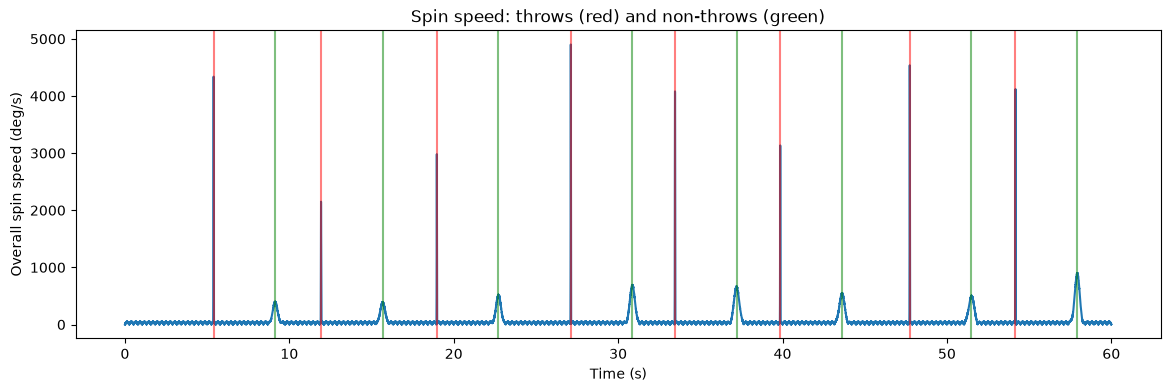

In [24]:
plt.figure(figsize=(14, 4))
plt.plot(df['time_s'], gyro_mag)

for i in throws['event_time_s']:
    plt.axvline(i, color="red", alpha=0.5)

for i in swings['event_time_s']:
    plt.axvline(i, color="green", alpha=0.5)

plt.title("Spin speed: throws (red) and non-throws (green)")
plt.xlabel("Time (s)")
plt.ylabel("Overall spin speed (deg/s)")
plt.show()

In [25]:
print('hi')

hi


## Part B: the threshold detector

In [26]:
toy = pd.DataFrame({"time_s": [0.4, 1.6, 27.1]})
toy["window"] = (toy["time_s"] // 1).astype(int)
toy

,time_s,window
0,0.4,0
1,1.6,1
2,27.1,27


In [27]:
df["window"] = (df["time_s"] // 1).astype(int)
df["gyro_mag"] = gyro_mag
df[["time_s", "window", "gyro_mag"]].head()

,time_s,window,gyro_mag
0,0.000,0,1.964248
1,0.001,0,5.645461
2,0.002,0,3.327207
3,0.003,0,6.533779
4,0.004,0,0.762138


In [28]:
df

,time_s,gx,gy,gz,ax,ay,az,window,gyro_mag
0,0.000,0.314700,-1.607008,1.084785,0.002820,0.012064,0.981732,0,1.964248
1,0.001,4.302834,3.144411,-1.862668,-0.014538,0.021140,1.019863,0,5.645461
2,0.002,-3.014653,-1.263530,0.621019,-0.010477,0.003275,1.018717,0,3.327207
3,0.003,-5.802815,0.252957,-2.992260,0.048790,0.017633,0.983330,0,6.533779
4,0.004,-0.634025,-0.420535,0.044897,0.004248,-0.002296,1.021145,0,0.762138
...,...,...,...,...,...,...,...,...,...
59995,59.995,-0.744222,-1.279341,1.998049,0.011971,-0.025193,0.972145,59,2.486520
59996,59.996,-5.404739,-2.321580,-3.981364,-0.023924,-0.024352,0.983035,59,7.102971
59997,59.997,-0.528172,2.480683,1.705658,-0.012265,0.020655,0.999053,59,3.056473
59998,59.998,-4.696312,-0.746099,-0.238987,-0.036442,-0.005642,1.003420,59,4.761211


In [29]:
peaks=df.groupby("window")["gyro_mag"].max()
peaks

window
0       52.875551
1       52.783543
2       54.073579
3       53.350789
4       53.367132
5     4338.251844
6       52.811551
7       53.797900
8      254.018304
9      399.781163
10      54.607373
11    2149.529838
12      55.389873
13      53.380920
14      53.357972
15     394.365528
16      54.882603
17      54.259157
18    2981.568587
19      52.837571
20      53.764978
21      54.109777
22     522.589565
23      95.204371
24      57.161322
25      53.916229
26      54.334685
27    4901.206575
28      56.977900
29      54.977719
30     693.874968
31     476.208704
32      52.278407
33    4080.434324
34      54.184177
35      54.741645
36     298.118716
37     669.139937
38      53.796586
39    3134.096190
40      54.673223
41      54.043919
42      53.792851
43     551.602484
44      51.757335
45      52.799217
46      53.361249
47    4537.185041
48      53.939518
49      55.443838
50      52.736301
51     507.284595
52      54.277647
53      53.944706
54    4120.485037
55 

In [30]:
len(peaks), peaks.max(), peaks.idxmax()

(60, np.float64(4901.206574580212), np.int64(27))

In [31]:
throws

,event_time_s,label,true_peak_dps
0,5.393809,throw,5021.216869
2,11.928604,throw,2157.502763
4,18.971310,throw,2974.022361
6,27.120936,throw,4907.067178
8,33.459940,throw,5047.055059
10,39.861702,throw,3144.810593
12,47.738363,throw,4555.785182
14,54.170801,throw,4119.960431


In [32]:
throw_windows=(throws["event_time_s"]//1).astype(int) #We are calculating the window here and making it a specific integer with .astype
truth=peaks.index.isin(throw_windows)
throw_windows


0      5
2     11
4     18
6     27
8     33
10    39
12    47
14    54
Name: event_time_s, dtype: int64

In [33]:
truth #This truth variable although confusiing at first, tells us what windows have a throws at that specific window. Ex. 5, 11, 18, 27, 33, etc.


array([False, False, False, False, False,  True, False, False, False,
       False, False,  True, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False,  True, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
        True, False, False, False, False, False])

In [34]:
threshold=1500
pred=peaks>threshold
pred


window
0     False
1     False
2     False
3     False
4     False
5      True
6     False
7     False
8     False
9     False
10    False
11     True
12    False
13    False
14    False
15    False
16    False
17    False
18     True
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27     True
28    False
29    False
30    False
31    False
32    False
33     True
34    False
35    False
36    False
37    False
38    False
39     True
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47     True
48    False
49    False
50    False
51    False
52    False
53    False
54     True
55    False
56    False
57    False
58    False
59    False
Name: gyro_mag, dtype: bool

In [35]:
pred.sum() #Amount of throws in this specific time frame that exceeds the pre-fit threshold

np.int64(8)

In [36]:
truth.sum()

np.int64(8)

In [37]:
len(truth)

60

In [38]:
a = pd.Series([True, True, False, False])
b = pd.Series([True, False, True, False])

In [39]:
a&b

0     True
1    False
2    False
3    False
dtype: bool

In [40]:
a &~b

0    False
1     True
2    False
3    False
dtype: bool

Both work on lists of True and False, item by item:

Symbol	Meaning	Example
&	and: True only where both are True	True & False is False
~	not: flips every True to False and every False to True	~True is False

In [41]:
tp = (pred & truth).sum() #This checks, are both the prediction and the truth true? 8
fp = (pred & ~truth).sum() #This checks, dectector said its a throw but it really wasn't 0
fn = (~pred & truth).sum() # This tells us if the detector said its not a throw but the truth said it was a throw 0 
tn = (~pred & ~truth).sum() # This tells us if the detector said its not a throw and the truth also said it wasn't a throw 52
print(tp, fp, fn, tn)

8 0 0 52


In [42]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
precision, recall

(np.float64(1.0), np.float64(1.0))

In [43]:
for threshold in [100,300, 1000, 1200, 2000, 3000, 6000]:
    pred=peaks>threshold
    #Same format as above
    tp= (pred & truth).sum()
    fp= (pred & ~truth).sum()
    fn=(~pred & truth).sum() 
    tn= (~pred & ~truth).sum()    
    print(threshold, tp,fp,fn,tn)

100 8 12 0 40
300 8 10 0 42
1000 8 0 0 52
1200 8 0 0 52
2000 8 0 0 52
3000 6 0 2 52
6000 0 0 8 52


In [44]:
peaks[~truth].max(), peaks[truth].min()


(np.float64(902.3469885868881), np.float64(2149.529838295014))

(np.float64(902.3469885868881), np.float64(2149.529838295014))

In [48]:
for threshold in [900, 1500, 2100,2150]:
    pred=peaks>threshold
    #Same format as above
    tp= (pred & truth).sum()
    fp= (pred & ~truth).sum()
    fn=(~pred & truth).sum() 
    tn= (~pred & ~truth).sum()    
    print(threshold, tp,fp,fn,tn)

900 8 1 0 51
1500 8 0 0 52
2100 8 0 0 52
2150 7 0 1 52


Reflection on notebook: Based on the notebook and the findings of the DUMMY CSV data, I have figured out that the perfect range is from 902 to 2149.5 because this is the range when tehre are little to none false positives (fp) or false negatives (fn) and more of the predictions are true positives(tp) and true negatives (tn). This csv data, unlike real data is clearly easy because it is distinguishable when something is a throw vs. nonthrow. In a real data: it will be a lot harder and messier because if someone swings their arm really, really much faster, or if the machine algorithm predicts something wrong, those two scenarios are where things could go wrong. Imbalance in the values or misalignment could happen, and this could lead to inaccurate results. My chosen threshold, based on all the data analysis, is 2,100 for a throw. This is the threshold because there were lots of true positives and true negatives, and no false positives or false negatives, so all the predictions were correct. Also, this is the threshold where I saw lots of throws were reaching. I did not want to set it too low because there would be some possibilities where people could just swing their arm really, really hard without actually throwing it. That could lead to 1,500, but it wouldn't reach 2,100. That's why I choose 2,100 instead of 1,500 as well. 
Currently, this threshold is also provisional and will be recalibrated on real training data through a volunteer pitcher. 